In [10]:
import pandas as pd
import os

# === FILE PATH ===
dna_path = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/SV_df_unqiue.csv"

# === LOAD FILE ===
dna_df = pd.read_csv(dna_path)
dna_df.columns = dna_df.columns.str.strip()

# === SPLIT PDO vs TUMOR ===
pdo_df = dna_df[dna_df["sample"].astype(str).str.strip().str.startswith("IPM", na=False)].copy()
tumor_df = dna_df[dna_df["sample"].astype(str).str.strip().str.startswith("TP", na=False)].copy()

# === EXTRACT FUSIONS (UNIQUE) ===
def extract_fusions(df, column):
    valid = df[column].dropna().astype(str).str.strip()
    valid = valid[~valid.isin(["", "-", "not_applicable"])]
    fusions = [fusion.strip() for row in valid for fusion in str(row).split(";") if fusion.strip()]
    return set(fusions)

# === EXTRACT FUSIONS (INCLUDING DUPLICATES) ===
def extract_fusions_with_duplicates(df, column):
    valid = df[column].dropna().astype(str).str.strip()
    valid = valid[~valid.isin(["", "-", "not_applicable"])]
    fusions = [fusion.strip() for row in valid for fusion in str(row).split(";") if fusion.strip()]
    return fusions

pdo_fusions = extract_fusions(pdo_df, "PutativeGeneFusion")
tumor_fusions = extract_fusions(tumor_df, "PutativeGeneFusion")

pdo_fusions_all = extract_fusions_with_duplicates(pdo_df, "PutativeGeneFusion")
tumor_fusions_all = extract_fusions_with_duplicates(tumor_df, "PutativeGeneFusion")

# === COMPARE SETS ===
pdo_only = pdo_fusions - tumor_fusions
tumor_only = tumor_fusions - pdo_fusions
shared = pdo_fusions & tumor_fusions

# === OUTPUT ===
print(f"Total gene fusions in PDO (including duplicates): {len(pdo_fusions_all)}")
print(f"Total gene fusions in Tumor (including duplicates): {len(tumor_fusions_all)}")

print(f"Total unique gene fusions in PDO: {len(pdo_fusions)}")
print(f"Total unique gene fusions in Tumor: {len(tumor_fusions)}")
print(f"PDO-only fusions: {len(pdo_only)}")
print(f"Tumor-only fusions: {len(tumor_only)}")
print(f"Shared fusions: {len(shared)}")

print("\nShared fusions:")
for fusion in sorted(shared):
    print(f" - {fusion}")

Total gene fusions in PDO (including duplicates): 634
Total gene fusions in Tumor (including duplicates): 544
Total unique gene fusions in PDO: 618
Total unique gene fusions in Tumor: 532
PDO-only fusions: 615
Tumor-only fusions: 529
Shared fusions: 3

Shared fusions:
 - AC109780.2-KNG1
 - CCDC170-ESR1
 - MIPOL1-TTC6


In [37]:
import pandas as pd

# === FILE PATHS ===
dna_path = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/SV_df_unqiue.csv"
rna_path = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/SVs/RNA_SV_df.csv"

# === LOAD FILES ===
dna_df = pd.read_csv(dna_path)
rna_df = pd.read_csv(rna_path)

# === EXTRACT FUSIONS ===
def extract_fusions(df, column):
    valid = df[column].dropna()
    valid = valid[~valid.isin(["", "-", "not_applicable"])]
    fusions = [fusion.strip() for row in valid for fusion in str(row).split(";") if fusion.strip()]
    return set(fusions)

dna_fusions = extract_fusions(dna_df, "PutativeGeneFusion")
rna_fusions = extract_fusions(rna_df, "RNAFusion")

# === FIND OVERLAP ===
overlap = dna_fusions & rna_fusions

# === OUTPUT ===
print(f"Unique DNA fusion count: {len(dna_fusions)}")
print(f"Unique RNA fusion count: {len(rna_fusions)}")
print(f"Overlapping fusions across OGM and RNASeq: {len(overlap)}\n")

for fusion in sorted(overlap):
    print(f" - {fusion}")

# === OPTIONAL: Save to file in same folder as RNA file ===
import os
overlap_df = pd.DataFrame(sorted(overlap), columns=["OverlappingFusions"])
overlap_path = os.path.join(os.path.dirname(rna_path), "overlapping_fusions.csv")
overlap_df.to_csv(overlap_path, index=False)
print(f"\n Overlapping fusion list saved to: {overlap_path}")


Unique DNA fusion count: 1147
Unique RNA fusion count: 383
Overlapping fusions across OGM and RNASeq: 37

 - AL109615.3-AL583836.1
 - ALCAM-AL136418.1
 - AP2B1-SKAP1
 - APBB2-PTPRR
 - ARHGEF7-ATP11A
 - ATXN2-BRAP
 - BACE2-MX1
 - CDC14A-LSAMP
 - CNOT1-GOT2
 - CTC1-STX8
 - DENND5A-SORL1
 - EDC3-PREX1
 - ESR1-ARNT2
 - ITGAV-GULP1
 - MED13-ABCA6
 - METTL16-BRCA1
 - NFE2L3-CBX3
 - NIPBL-AC034114.2
 - NUP107-OTOGL
 - OXNAD1-PLCL2
 - PCBP1-AS1-PPP1R1B
 - PITPNC1-SDK2
 - PPFIA1-ARHGAP32
 - PPFIBP2-KMT5B
 - PPP2R5E-PIGH
 - PPP3CB-SAFB
 - PRKACB-PAH
 - PVT1-PSIP1
 - RFC1-SMIM14
 - SPHK2-SEC1P
 - SPON2-FBXL5
 - TAB3-DMD
 - TPST1-AC027644.4
 - TPST1-RABGEF1
 - TUSC3-ANO1
 - UNC13B-PLEKHG6
 - UVRAG-MYO7A

 Overlapping fusion list saved to: /ix1/alee/LO_LAB/Personal/Rahul/BioNano/SVs/overlapping_fusions.csv


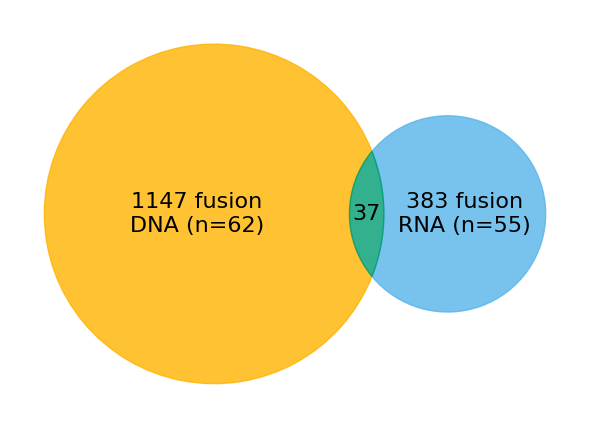

Saved Venn diagram with total fusion counts inside circles at: /ix1/alee/LO_LAB/Personal/Rahul/BioNano/SVs/rna_dna_fusions_venn.png


In [33]:
import matplotlib.pyplot as plt
from matplotlib_venn import venn2
import os

# Unique Fusion count
rna_fusions = 383
dna_fusions = 1147
overlap = 37

# Venn subsets (for shape only)
only_rna = rna_fusions - overlap
only_dna = dna_fusions - overlap

# Output path
output_dir = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/SVs"
output_file = os.path.join(output_dir, "rna_dna_fusions_venn.png")

# Create plot
plt.figure(figsize=(6, 6))
venn = venn2(subsets=(only_dna, only_rna, overlap))  # DNA on left, RNA on right

# Set custom colors for regions
venn.get_patch_by_id('10').set_color('#FFB300')   # DNA only - amber
venn.get_patch_by_id('01').set_color('#56B4E9')   # RNA only - light blue
venn.get_patch_by_id('11').set_color('#009E73')   # Overlap - green

# Optional: transparency
venn.get_patch_by_id('10').set_alpha(0.8)
venn.get_patch_by_id('01').set_alpha(0.8)
venn.get_patch_by_id('11').set_alpha(0.8)

# Set custom labels
venn.get_label_by_id('10').set_text(f"{dna_fusions} fusion\nDNA (n=62)")
venn.get_label_by_id('01').set_text(f"{rna_fusions} fusion\nRNA (n=55)")
venn.get_label_by_id('11').set_text(f"{overlap}")

# Set font sizes
venn.get_label_by_id('10').set_fontsize(16)
venn.get_label_by_id('01').set_fontsize(16)
venn.get_label_by_id('11').set_fontsize(16)

# Remove default set labels
for label in venn.set_labels:
    if label:
        label.set_visible(False)

# Title and save
plt.tight_layout()
plt.savefig(output_file, dpi=300)

plt.show()  # <- Show the plot before closing
plt.close()

print(f"Saved Venn diagram with total fusion counts inside circles at: {output_file}")
